In [23]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/mumbai_cleaned.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (18846, 26)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,...,Description,Property Image,Price_per_m2,Suspicious_Price,Price_num,Area_num,BHK_num,Bathrooms_num,Balconies_num,Furnished_clean
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,...,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,93.333333,False,70000.0,750.0,1.0,1.0,NaN,Furnished
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,...,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,70.707071,False,140000.0,1980.0,3.0,4.0,4.0,Unfurnished
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,...,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,119.346734,False,190000.0,1592.0,3.0,3.0,1.0,Unfurnished
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,...,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,84.291188,False,110000.0,1305.0,3.0,3.0,3.0,Unfurnished
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,...,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,103.703704,False,140000.0,1350.0,3.0,3.0,NaN,Unfurnished


In [24]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [25]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [26]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nChecking scikit-learn:")
%pip show scikit-learn


Python executable:
c:\Users\sanja\anaconda3\python.exe

Python version:
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]

Checking scikit-learn:
Name: scikit-learn
Version: 1.9.1
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License-Expression: BSD-3-Clause
Location: c:\Users\sanja\anaconda3\Lib\site-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: imbalanced-learn, sklearn-compat
Note: you may need to restart the kernel to use updated packages.


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("All scikit-learn imports are working!")

All scikit-learn imports are working!


Can we predict monthly rental prices in Mumbai based on property characteristics?

In [28]:
print("Dataset shape:", df.shape)

print("\nAvailable columns:")
for col in df.columns:
    print(col)

print("\nColumn types:")
display(df.dtypes)

Dataset shape: (18846, 26)

Available columns:
Title
Price
Area
BHK
Bathrooms
Furnished
Balconies
Floor
Ownership
Facing
Amenities
Transaction Type
Property Type
Location
Year of Construction
Is Luxury
Description
Property Image
Price_per_m2
Suspicious_Price
Price_num
Area_num
BHK_num
Bathrooms_num
Balconies_num
Furnished_clean

Column types:


Title                       str
Price                   float64
Area                    float64
BHK                     float64
Bathrooms               float64
Furnished                   str
Balconies               float64
Floor                   float64
Ownership                   str
Facing                      str
Amenities                   str
Transaction Type            str
Property Type               str
Location                    str
Year of Construction    float64
Is Luxury                   str
Description                 str
Property Image              str
Price_per_m2            float64
Suspicious_Price           bool
Price_num               float64
Area_num                float64
BHK_num                 float64
Bathrooms_num           float64
Balconies_num           float64
Furnished_clean             str
dtype: object

In [29]:
print(df.columns.tolist())

['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image', 'Price_per_m2', 'Suspicious_Price', 'Price_num', 'Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean']


## 3. Train/Test Split

We split the dataset into 80% training data and 20% test data.

The training set will be used for model training, cross-validation,
and hyperparameter tuning.

The test set will remain untouched until the final evaluation
to assess how well the model generalizes to unseen properties.

In [30]:
from sklearn.model_selection import train_test_split

# Define the target and selected features
target = "Price_num"

features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num",
    "Furnished_clean",
    "Facing",
    "Location",
    "Property Type"
]

# Verify that all columns exist
assert all(col in df.columns for col in features + [target])

# Keep only rows with a valid target
model_df = df.dropna(subset=[target]).copy()

X = model_df[features]
y = model_df[target]

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (15076, 8)
Testing features: (3770, 8)
Training target: (15076,)
Testing target: (3770,)


## 3. Preprocessing Pipeline

Numerical and categorical features require different preprocessing.

- Numerical features: median imputation and standardization.
- Categorical features: most-frequent imputation and one-hot encoding.

All preprocessing is fitted only on training data through a
scikit-learn pipeline to prevent data leakage.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical and categorical columns
numeric_features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num"
]

categorical_features = [
    "Furnished_clean",
    "Facing",
    "Location",
    "Property Type"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## Underfitting and Overfitting Analysis
We investigated underfitting and overfitting using a Decision Tree Regressor to predict monthly rental prices in Mumbai. We varied the maximum tree depth to examine how model complexity affects prediction performance.

At a depth of 1, the model showed signs of underfitting, with high training and validation errors. As the depth increased, validation RMSE decreased, reaching its lowest value at a depth of 5.

Beyond a depth of 5, validation RMSE increased even though training RMSE continued to decrease. This indicates overfitting: the model learns the training data more closely but becomes less effective at predicting unseen properties.

Among the six tree depths tested, a maximum depth of 5 achieved the lowest validation RMSE. We therefore selected it as our current candidate for final evaluation on the held-out test set.

This experiment demonstrates that increasing model complexity does not always improve predictive performance. Selecting an appropriate level of complexity is important for building a model that generalises to unseen rental listings.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Split the training data into a fitting set and a validation set
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

# Test different levels of model complexity
depths = [1, 2, 3, 5, 10, None]

results = []

for depth in depths:

    # Create a pipeline using our existing preprocessing
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    # Train the model
    model.fit(X_fit, y_fit)

    # Make predictions on training and validation data
    train_predictions = model.predict(X_fit)
    val_predictions = model.predict(X_val)

    # Calculate RMSE for both datasets
    train_rmse = mean_squared_error(
        y_fit, train_predictions
    ) ** 0.5

    val_rmse = mean_squared_error(
        y_val, val_predictions
    ) ** 0.5

    # Calculate R² scores
    train_r2 = r2_score(y_fit, train_predictions)
    val_r2 = r2_score(y_val, val_predictions)

    results.append({
        "Max Depth": str(depth),
        "Training RMSE": train_rmse,
        "Validation RMSE": val_rmse,
        "Training R²": train_r2,
        "Validation R²": val_r2
    })

# Display the results
results_df = pd.DataFrame(results)

display(results_df.round(2))


,Max Depth,Training RMSE,Validation RMSE,Training R²,Validation R²
0,1,103880.85,93969.27,0.39,0.43
1,2,86355.20,82329.78,0.58,0.56
2,3,80549.70,77863.26,0.63,0.61
3,5,76347.14,75265.82,0.67,0.63
4,10,60455.01,79280.67,0.79,0.59
5,None,28752.10,87360.22,0.95,0.50


Plotting the results from the analysis of underfitting and overfitting.

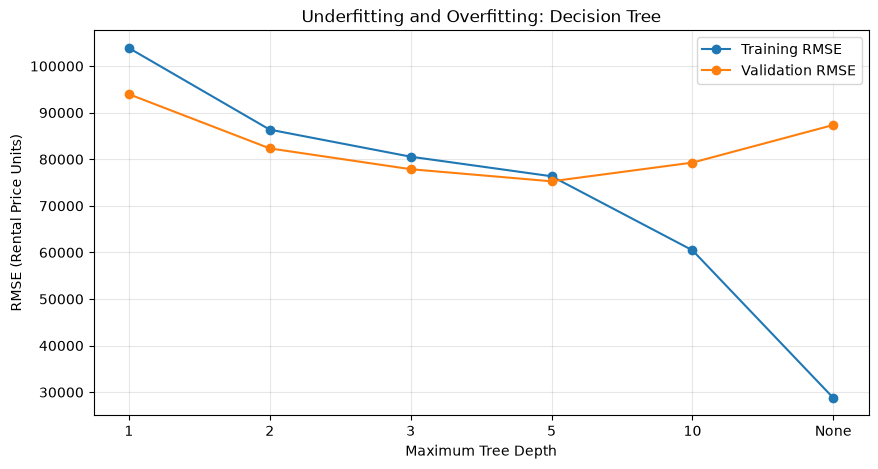

In [33]:
# Plot training and validation errors
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Max Depth"],
    results_df["Training RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    results_df["Max Depth"],
    results_df["Validation RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.title("Underfitting and Overfitting: Decision Tree")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE (Rental Price Units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Comparison of Model Complexity

We compared three Decision Tree Regressor models with maximum depths of 1, 5, and unlimited depth to investigate underfitting and overfitting.

The model with a depth of 1 showed signs of underfitting, with a training RMSE of 103,880.85 and a validation RMSE of 93,969.27. This indicates that the model was too simple to capture the relationships between property characteristics and rental prices effectively.

The model with a depth of 5 achieved the lowest validation RMSE of 75,265.82. Its training RMSE was 76,347.14, indicating a relatively small difference between training and validation errors.

The unrestricted decision tree achieved a much lower training RMSE of 28,752.10, but its validation RMSE increased to 87,360.22. This indicates overfitting, as the model performed considerably better on the training data than on unseen validation data.

Based on these results, we selected a maximum tree depth of 5 as the best candidate among the three models compared. This experiment demonstrates the importance of controlling model complexity to improve generalisation.

In [34]:
from sklearn.metrics import mean_absolute_error

# Select three model complexities for comparison
comparison_depths = [1, 5, None]

comparison_results = []

for depth in comparison_depths:

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_fit, y_fit)

    train_predictions = model.predict(X_fit)
    val_predictions = model.predict(X_val)

    comparison_results.append({
        "Max Depth": str(depth),
        "Training MAE": mean_absolute_error(
            y_fit, train_predictions
        ),
        "Validation MAE": mean_absolute_error(
            y_val, val_predictions
        ),
        "Training RMSE": mean_squared_error(
            y_fit, train_predictions
        ) ** 0.5,
        "Validation RMSE": mean_squared_error(
            y_val, val_predictions
        ) ** 0.5
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(2))

,Max Depth,Training MAE,Validation MAE,Training RMSE,Validation RMSE
0,1,56492.22,55652.50,103880.85,93969.27
1,5,38684.03,40316.60,76347.14,75265.82
2,None,12619.39,42322.16,28752.10,87360.22


Maximum depth = 5 means we allow the decision tree to grow up to five levels deep, and in our experiment, this gave the lowest validation prediction error among the depths we tested.

In [35]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select the best depth based on validation results
best_depth = 5

# Create the final model
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=best_depth,
        random_state=42
    ))
])

# Train on the full original training set
final_model.fit(X_train, y_train)

# Predict rental prices for the unseen test set
test_predictions = final_model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(
    y_test, test_predictions
)

test_rmse = mean_squared_error(
    y_test, test_predictions
) ** 0.5

test_r2 = r2_score(
    y_test, test_predictions
)

# Display results
print("Final Model: Decision Tree Regressor")
print("Selected Maximum Depth:", best_depth)
print(f"Test MAE: {test_mae:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")
print(f"Test R²: {test_r2:.3f}")

Final Model: Decision Tree Regressor
Selected Maximum Depth: 5
Test MAE: 40528.67
Test RMSE: 83764.35
Test R²: 0.611


## Cross-Validation Analysis

We performed 5-fold cross-validation using a Decision Tree Regressor with a maximum depth of 5. The model achieved a mean validation RMSE of 79,945.09, a mean validation MAE of 39,698.33, and a mean validation R² score of 0.628.

The validation RMSE varied across the five folds, ranging from 65,970.28 to 105,663.98. The standard deviation of 16,066.60 indicates that predictive performance was not consistent across all subsets of the training data.

This variation suggests that the model may find some groups of rental properties more difficult to predict than others. Further investigation would be required to identify the reasons for these differences.

Overall, cross-validation provides a broader assessment of model performance than a single validation split. The results support further evaluation of the depth-5 decision tree, while highlighting the need to examine its prediction errors and compare it against a simple baseline model.

In [36]:
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# Create the decision tree model using the existing preprocessing
cv_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

# Perform 5-fold cross-validation on the training data
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    return_train_score=True
)

# Convert negative error scores into positive values
cv_summary = pd.DataFrame({
    "Fold": range(1, 6),
    "Training RMSE": -cv_results["train_rmse"],
    "Validation RMSE": -cv_results["test_rmse"],
    "Training MAE": -cv_results["train_mae"],
    "Validation MAE": -cv_results["test_mae"],
    "Validation R²": cv_results["test_r2"]
})

display(cv_summary.round(2))

print("\nAverage cross-validation results:")
print(f"Mean Validation RMSE: {-cv_results['test_rmse'].mean():.2f}")
print(f"Mean Validation MAE: {-cv_results['test_mae'].mean():.2f}")
print(f"Mean Validation R²: {cv_results['test_r2'].mean():.3f}")

print("\nVariation in validation RMSE:")
print(f"Standard Deviation: {cv_results['test_rmse'].std():.2f}")

,Fold,Training RMSE,Validation RMSE,Training MAE,Validation MAE,Validation R²
0,1,77974.30,67898.84,39119.50,37571.81,0.69
1,2,78180.91,65970.28,39276.84,37939.15,0.68
2,3,73947.16,92112.05,37994.43,41737.87,0.60
3,4,78169.08,68080.29,38860.33,39339.77,0.68
4,5,67366.61,105663.98,37847.37,41903.05,0.49



Average cross-validation results:
Mean Validation RMSE: 79945.09
Mean Validation MAE: 39698.33
Mean Validation R²: 0.628

Variation in validation RMSE:
Standard Deviation: 16066.60


Plotting the folds in Cross-Validation.

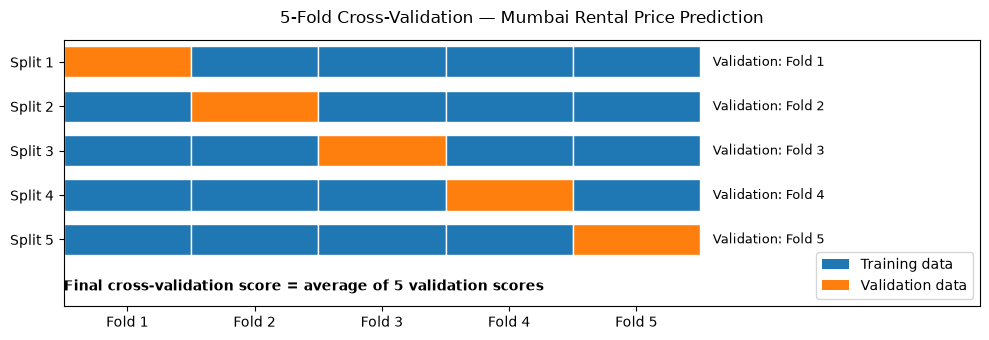

In [37]:
import matplotlib.pyplot as plt

# Number of folds
k = 5

fig, ax = plt.subplots(figsize=(10, 3.5))

# Draw the training and validation folds
for split in range(k):
    for fold in range(k):
        is_validation = fold == split

        ax.barh(
            y=split,
            width=1,
            left=fold,
            height=0.7,
            edgecolor="white",
            color="tab:orange" if is_validation else "tab:blue"
        )

    # Label each validation fold
    ax.text(
        k + 0.1,
        split,
        f"Validation: Fold {split + 1}",
        va="center",
        fontsize=9
    )

# Add the average score annotation
ax.text(
    0,
    k + 0.15,
    "Final cross-validation score = average of 5 validation scores",
    fontweight="bold",
    fontsize=10
)

# Configure axes
ax.set_yticks(range(k))
ax.set_yticklabels([f"Split {i + 1}" for i in range(k)])

ax.set_xticks([i + 0.5 for i in range(k)])
ax.set_xticklabels([f"Fold {i + 1}" for i in range(k)])

ax.invert_yaxis()
ax.set_xlim(0, k + 2.2)
ax.set_ylim(k + 0.5, -0.5)
ax.grid(False)

ax.set_title(
    "5-Fold Cross-Validation — Mumbai Rental Price Prediction",
    fontsize=12,
    pad=12
)

# Add legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="tab:blue", label="Training data"),
    Patch(facecolor="tab:orange", label="Validation data")
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True
)

plt.tight_layout()
plt.show()

## Baseline Model Comparison

To evaluate whether using property characteristics improves rental-price prediction, we compared our Decision Tree Regressor with a baseline model that predicts the median rental price from the training data for every property.

The baseline achieved a test MAE of 67,123.75, a test RMSE of 140,522.95, and an R² score of -0.095.

In comparison, our Decision Tree with a maximum depth of 5 achieved a test MAE of 40,528.67, a test RMSE of 83,764.35, and an R² score of 0.611.

Compared with the baseline, the Decision Tree reduced MAE by approximately 39.6% and RMSE by approximately 40.4%. It also achieved a substantially higher R² score.

These results suggest that property characteristics provide useful information for predicting rental prices in our dataset. However, the remaining prediction errors indicate that the model could still be improved.

In [38]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Create a simple baseline model
baseline_model = DummyRegressor(strategy="median")

# Train the baseline using the original training data
baseline_model.fit(X_train, y_train)

# Predict prices for the original test data
baseline_predictions = baseline_model.predict(X_test)

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = mean_squared_error(
    y_test, baseline_predictions
) ** 0.5

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

# Display results
print("Baseline Model: Median Prediction")
print(f"Test MAE: {baseline_mae:.2f}")
print(f"Test RMSE: {baseline_rmse:.2f}")
print(f"Test R²: {baseline_r2:.3f}")

Baseline Model: Median Prediction
Test MAE: 67123.75
Test RMSE: 140522.95
Test R²: -0.095


In [39]:
# Compare the baseline and Decision Tree on the same test set
comparison_test = pd.DataFrame({
    "Model": [
        "Baseline (Median)",
        "Decision Tree (Depth 5)"
    ],
    "Test MAE": [
        baseline_mae,
        test_mae
    ],
    "Test RMSE": [
        baseline_rmse,
        test_rmse
    ],
    "Test R²": [
        baseline_r2,
        test_r2
    ]
})

display(comparison_test.round(3))

,Model,Test MAE,Test RMSE,Test R²
0,Baseline (Median),67123.754,140522.950,-0.095
1,Decision Tree (Depth 5),40528.666,83764.353,0.611


Inspecting Available Columns

In [40]:
# Display all columns in the original dataset
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Title', 'Price', 'Area', 'BHK', 'Bathrooms', 'Furnished', 'Balconies', 'Floor', 'Ownership', 'Facing', 'Amenities', 'Transaction Type', 'Property Type', 'Location', 'Year of Construction', 'Is Luxury', 'Description', 'Property Image', 'Price_per_m2', 'Suspicious_Price', 'Price_num', 'Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean']


## Data Leakage Check

Our target variable is `Price_num`, which represents the rental price we want to predict.

We checked the eight features used by our Decision Tree Regressor and confirmed that the following columns are excluded from the model: `Price`, `Price_num`, `Price_per_m2`, and `Suspicious_Price`.

This is important because `Price_per_m2` may be calculated using the rental price, while `Suspicious_Price` may encode information derived from the target. Including such features could allow the model to access information that would not be available when predicting rent for a new property.

Our model instead uses property characteristics such as area, number of bedrooms, bathrooms, balconies, furnishing, facing, location, and property type.

This check confirms that the identified columns are not directly included in the model. Further checks of feature creation and preprocessing are still necessary to establish that the complete workflow is free from data leakage.

Investigating Potential Data Leakage

In [41]:
import numpy as np
import pandas as pd

# Check the relationship between price, area, and price per square metre
leakage_check = df[
    ["Price_num", "Area_num", "Price_per_m2"]
].copy()

# Remove rows with missing or invalid values
leakage_check = leakage_check.dropna()

# Avoid division by zero
leakage_check = leakage_check[
    (leakage_check["Area_num"] > 0) &
    (leakage_check["Price_num"] > 0)
]

# Calculate price per square metre from the target and area
leakage_check["Calculated_Price_per_m2"] = (
    leakage_check["Price_num"] / leakage_check["Area_num"]
)

# Compare the calculated value with the existing feature
leakage_check["Difference"] = (
    leakage_check["Price_per_m2"] -
    leakage_check["Calculated_Price_per_m2"]
).abs()

print("Number of rows checked:", len(leakage_check))

print(
    "Mean absolute difference:",
    leakage_check["Difference"].mean()
)

print(
    "Maximum absolute difference:",
    leakage_check["Difference"].max()
)

display(leakage_check.head())

Number of rows checked: 18846
Mean absolute difference: 1.8131404145130567e-15
Maximum absolute difference: 1.1368683772161603e-13


,Price_num,Area_num,Price_per_m2,Calculated_Price_per_m2,Difference
0,70000.0,750.0,93.333333,93.333333,1.421085e-14
1,140000.0,1980.0,70.707071,70.707071,0.000000e+00
2,190000.0,1592.0,119.346734,119.346734,0.000000e+00
3,110000.0,1305.0,84.291188,84.291188,1.421085e-14
4,140000.0,1350.0,103.703704,103.703704,1.421085e-14


Compare model performance with and without the potential leakage feature

In [42]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Compare the existing features with a version excluding Price_per_m2
X_train_with = X_train.copy()
X_test_with = X_test.copy()

X_train_without = X_train.drop(
    columns=["Price_per_m2"],
    errors="ignore"
)

X_test_without = X_test.drop(
    columns=["Price_per_m2"],
    errors="ignore"
)

# Reuse the same preprocessing and model settings.
# Rebuild the preprocessing pipeline for each feature set if needed.
print("Training features with potential leakage:", X_train_with.shape[1])
print("Training features without Price_per_m2:", X_train_without.shape[1])

Training features with potential leakage: 8
Training features without Price_per_m2: 8


In [43]:
print("Features used by our model:")
print(X_train.columns.tolist())

print("\nIs Price_per_m2 in X_train?")
print("Price_per_m2" in X_train.columns)

print("\nNumber of features:", len(X_train.columns))

Features used by our model:
['Area_num', 'BHK_num', 'Bathrooms_num', 'Balconies_num', 'Furnished_clean', 'Facing', 'Location', 'Property Type']

Is Price_per_m2 in X_train?
False

Number of features: 8


In [44]:
# Check the relationship between the target and our input features

print("Target variable:", y_train.name)

print("\nFeatures used for prediction:")
for column in X_train.columns:
    print("-", column)

print("\nChecking for target leakage:")

# Features that should not be used if they are derived from the target
potential_leakage_features = [
    "Price",
    "Price_num",
    "Price_per_m2",
    "Suspicious_Price"
]

for feature in potential_leakage_features:
    if feature in X_train.columns:
        print(f"WARNING: {feature} is included in the training features.")
    else:
        print(f"OK: {feature} is not included in the training features.")

Target variable: Price_num

Features used for prediction:
- Area_num
- BHK_num
- Bathrooms_num
- Balconies_num
- Furnished_clean
- Facing
- Location
- Property Type

Checking for target leakage:
OK: Price is not included in the training features.
OK: Price_num is not included in the training features.
OK: Price_per_m2 is not included in the training features.
OK: Suspicious_Price is not included in the training features.


Ensuring scikit learn is installed and working correctly to move forward to pipelines.

In [45]:
import sklearn

print("Scikit-learn imported successfully!")
print("Version:", sklearn.__version__)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

print("All imports working correctly!")

Scikit-learn imported successfully!
Version: 1.9.1
All imports working correctly!


Code cell to demonstrate the API using your existing rental dataset.

In [51]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

# Select the numerical features
numeric_features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num"
]

# 1. Create preprocessing objects
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# 2. Learn the imputation values from training data
X_train_imputed = imputer.fit_transform(
    X_train[numeric_features]
)

# 3. Learn the scaling parameters and transform training data
X_train_scaled = scaler.fit_transform(X_train_imputed)

# 4. Train a regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Imputer, scaler, and model fitted successfully.")
print("Original numerical shape:", X_train[numeric_features].shape)
print("Transformed numerical shape:", X_train_scaled.shape)

Imputer, scaler, and model fitted successfully.
Original numerical shape: (15076, 4)
Transformed numerical shape: (15076, 4)


Version 1: Preprocessing manually

In [52]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Select numerical features
small_features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num"
]

# Create preprocessing tools and model
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
model_manual = LinearRegression()

# 1. Fit and transform training data
X_train_step1 = imputer.fit_transform(
    X_train[small_features]
)

X_train_step2 = scaler.fit_transform(X_train_step1)

# 2. Train the model
model_manual.fit(X_train_step2, y_train)

# 3. Transform test data using learned parameters
X_test_step1 = imputer.transform(
    X_test[small_features]
)

X_test_step2 = scaler.transform(X_test_step1)

# 4. Generate predictions
predictions_manual = model_manual.predict(X_test_step2)

# 5. Evaluate
print(
    f"R² by hand: "
    f"{r2_score(y_test, predictions_manual):.4f}"
)

R² by hand: 0.6038


Version2: Using a Pipeline

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Create a pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Fit the complete pipeline on training data
numeric_pipeline.fit(
    X_train[small_features],
    y_train
)

# Predict on test data
predictions_pipeline = numeric_pipeline.predict(
    X_test[small_features]
)

# Evaluate
print(
    f"R² with Pipeline: "
    f"{r2_score(y_test, predictions_pipeline):.4f}"
)

R² with Pipeline: 0.6038


Compare the two approaches

In [54]:
print(
    "Manual preprocessing R²:",
    round(r2_score(y_test, predictions_manual), 4)
)

print(
    "Pipeline R²:",
    round(r2_score(y_test, predictions_pipeline), 4)
)

Manual preprocessing R²: 0.6038
Pipeline R²: 0.6038


A Pipeline reduces repetitive code, keeps preprocessing and model training together, and helps prevent data leakage by ensuring transformations are learned from training data. Our current pipeline uses only numerical features

Inspect the categories

In [55]:
categorical_features = [
    "Furnished_clean",
    "Facing",
    "Location",
    "Property Type"
]

for column in categorical_features:
    print(f"\n--- {column} ---")
    print("Number of categories:", df[column].nunique(dropna=True))
    print(df[column].value_counts(dropna=False).head(10))


--- Furnished_clean ---
Number of categories: 3
Furnished_clean
Semi-Furnished    8256
Unfurnished       5649
Furnished         4928
NaN                 13
Name: count, dtype: int64

--- Facing ---
Number of categories: 9
Facing
East            9397
North - East    2674
Unknown         2068
West            1850
North           1316
South -West      688
North - West     381
South - East     255
South            217
Name: count, dtype: int64

--- Location ---
Number of categories: 1
Location
Mumbai    18846
Name: count, dtype: int64

--- Property Type ---
Number of categories: 6
Property Type
Apartment                  18287
Residential House            380
Builder Floor Apartment      106
Villa                         53
Penthouse                     18
Service Apartment              2
Name: count, dtype: int64


One-hot encoding

In [57]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Select the Facing column from training data
facing_example = X_train[["Facing"]].head(10).copy()

# Step 1: Fill missing values
facing_imputer = SimpleImputer(strategy="most_frequent")
facing_filled = facing_imputer.fit_transform(facing_example)

# Step 2: Create the encoder with dense output
onehot = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
).set_output(transform="pandas")

# Step 3: Convert the filled data into a DataFrame
facing_filled_df = pd.DataFrame(
    facing_filled,
    columns=["Facing"],
    index=facing_example.index
)

# Step 4: Fit and transform the categorical data
facing_encoded = onehot.fit_transform(facing_filled_df)

# Display the result
display(facing_encoded)

,Facing_East,Facing_North - East,Facing_South -West,Facing_Unknown,Facing_West
12056,1.0,0.0,0.0,0.0,0.0
10359,0.0,0.0,0.0,0.0,1.0
1266,0.0,0.0,0.0,1.0,0.0
4602,1.0,0.0,0.0,0.0,0.0
7341,0.0,0.0,1.0,0.0,0.0
12368,0.0,1.0,0.0,0.0,0.0
5195,0.0,0.0,0.0,1.0,0.0
7698,0.0,1.0,0.0,0.0,0.0
12669,1.0,0.0,0.0,0.0,0.0
4140,1.0,0.0,0.0,0.0,0.0


Ordinal Encoding - Inspect furnishing categories

In [58]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

print("Furnishing categories in training data:")
print(sorted(X_train["Furnished_clean"].dropna().unique()))

Furnishing categories in training data:
['Furnished', 'Semi-Furnished', 'Unfurnished']


Apply ordinal encoding

In [59]:
# Define the meaningful category order
furnishing_order = [
    "Unfurnished",
    "Semi-Furnished",
    "Furnished"
]

# Select non-missing training values for this demonstration
furnishing_example = X_train[["Furnished_clean"]].dropna()

# Create and fit the encoder
ordinal_encoder = OrdinalEncoder(
    categories=[furnishing_order]
)

encoded_furnishing = ordinal_encoder.fit_transform(
    furnishing_example
)

# Compare original and encoded values
furnishing_comparison = pd.DataFrame({
    "Original": furnishing_example["Furnished_clean"].values,
    "Encoded": encoded_furnishing.ravel()
})

display(furnishing_comparison.head(10))

,Original,Encoded
0,Furnished,2.0
1,Semi-Furnished,1.0
2,Furnished,2.0
3,Semi-Furnished,1.0
4,Unfurnished,0.0
5,Furnished,2.0
6,Semi-Furnished,1.0
7,Semi-Furnished,1.0
8,Unfurnished,0.0
9,Semi-Furnished,1.0


Label Encoding - Facing type

In [61]:
from sklearn.preprocessing import LabelEncoder

# Use non-missing training values for demonstration
facing_values = X_train["Facing"].dropna().astype(str)

# Create and fit the encoder
label_encoder = LabelEncoder()
facing_codes = label_encoder.fit_transform(facing_values)

# Display the category-to-code mapping
label_mapping = pd.DataFrame({
    "Category": label_encoder.classes_,
    "Code": range(len(label_encoder.classes_))
})

display(label_mapping)

,Category,Code
0,East,0
1,North,1
2,North - East,2
3,North - West,3
4,South,4
5,South - East,5
6,South -West,6
7,Unknown,7
8,West,8


Target Encoding - Location. First we check the version of sklearn if it supports.

In [62]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


Encode locations - For the encoder to create one numerical feature representing the location's target-related information.

In [63]:
from sklearn.preprocessing import TargetEncoder

location_encoder = TargetEncoder(
    target_type="continuous",
    random_state=42
)

# Fit and transform using training data only
location_encoded = location_encoder.fit_transform(
    X_train[["Location"]],
    y_train
)

print("Original shape:", X_train[["Location"]].shape)
print("Encoded shape:", location_encoded.shape)

print("\nFirst five encoded values:")
print(location_encoded[:5])

Original shape: (15076, 1)
Encoded shape: (15076, 1)

First five encoded values:
[[111324.43321449]
 [111022.08780366]
 [111957.80955145]
 [111779.75986733]
 [111022.08780366]]


c:\Users\sanja\anaconda3\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Column Transformer - Combining numerical preprocessing and categorical encoding.

In [64]:
numeric_features = [
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num"
]

nominal_features = [
    "Furnished_clean",
    "Facing",
    "Location",
    "Property Type"
]

Create the preprocessing pipelines

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("nom", nominal_pipeline, nominal_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


Create the complete model Pipeline

In [66]:
from sklearn.linear_model import LinearRegression

full_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])

print("Complete rental prediction pipeline created!")

Complete rental prediction pipeline created!


Fit the Pipeline - For the Pipeline to learn the preprocessing parameters and trains the regression model using the training data.

In [67]:
full_pipeline.fit(X_train, y_train)

print("Pipeline trained successfully!")

Pipeline trained successfully!


Inspect the transformed feature names

In [68]:
feature_names = (
    full_pipeline
    .named_steps["preprocess"]
    .get_feature_names_out()
)

print("Original feature count:", X_train.shape[1])
print("Transformed feature count:", len(feature_names))

print("\nFirst 20 transformed feature names:")
print(feature_names[:20])

Original feature count: 8
Transformed feature count: 23

First 20 transformed feature names:
['num__Area_num' 'num__BHK_num' 'num__Bathrooms_num' 'num__Balconies_num'
 'nom__Furnished_clean_Furnished' 'nom__Furnished_clean_Semi-Furnished'
 'nom__Furnished_clean_Unfurnished' 'nom__Facing_East' 'nom__Facing_North'
 'nom__Facing_North - East' 'nom__Facing_North - West' 'nom__Facing_South'
 'nom__Facing_South - East' 'nom__Facing_South -West'
 'nom__Facing_Unknown' 'nom__Facing_West' 'nom__Location_Mumbai'
 'nom__Property Type_Apartment'
 'nom__Property Type_Builder Floor Apartment'
 'nom__Property Type_Penthouse']


Display the Pipeline diagram

In [69]:
from sklearn import set_config

set_config(display="diagram")

full_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Area_num','BHK_num','Bathrooms_num',...,'Facing','Location', 'Property Type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of col

Evaluate using cross-validation. 
To understand concepts of Consistent preprocessing.
Reduced risk of data leakage.
Easy model replacement.
Easier hyperparameter tuning.
Simpler cross-validation.

Evaluate using cross-validation

In [70]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    full_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print("Five-fold cross-validation results")
print("----------------------------------")

print(
    "Mean R²:",
    round(cv_results["test_r2"].mean(), 4)
)

print(
    "Mean MAE:",
    round(-cv_results["test_mae"].mean(), 2)
)

print(
    "Mean RMSE:",
    round(-cv_results["test_rmse"].mean(), 2)
)

Five-fold cross-validation results
----------------------------------
Mean R²: 0.6277
Mean MAE: 42471.45
Mean RMSE: 79730.51


R² measures how well the model explains variation in rental prices.
MAE measures the average absolute prediction error.
RMSE penalizes larger prediction errors more heavily.

Replace Linear Regression with Random Forest

In [71]:
from sklearn.ensemble import RandomForestRegressor

forest_pipeline = full_pipeline.set_params(
    model=RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )
)

print("Estimator replaced with RandomForestRegressor.")

Estimator replaced with RandomForestRegressor.


Inspect Pipeline parameters

In [72]:
params = full_pipeline.get_params()

parameters_to_check = [
    "model",
    "preprocess__num__imputer__strategy",
    "preprocess__num__scaler__with_mean",
    "preprocess__nom__encoder__handle_unknown"
]

for parameter in parameters_to_check:
    print(f"{parameter}: {params[parameter]}")

model: RandomForestRegressor(n_jobs=1, random_state=42)
preprocess__num__imputer__strategy: median
preprocess__num__scaler__with_mean: True
preprocess__nom__encoder__handle_unknown: ignore


Create the helper function: Reusable helper

In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def make_pipeline_for(
    model,
    numeric,
    nominal,
    scale=True,
    nominal_encoder=None
):
    """
    Create a preprocessing and model pipeline.

    Parameters
    ----------
    model : scikit-learn estimator
        The regression model to train.

    numeric : list
        Numerical feature names.

    nominal : list
        Categorical feature names.

    scale : bool
        Whether to standardize numerical features.

    nominal_encoder : transformer or None
        Categorical encoder. Defaults to OneHotEncoder.

    Returns
    -------
    Pipeline
        A complete preprocessing and prediction pipeline.
    """

    # Numerical preprocessing
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_pipeline = Pipeline(
        steps=numeric_steps
    )

    # Default categorical encoder
    if nominal_encoder is None:
        nominal_encoder = OneHotEncoder(
            handle_unknown="ignore"
        )

    # Categorical preprocessing
    nominal_pipeline = Pipeline(steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        ("encoder", nominal_encoder)
    ])

    # Apply preprocessing to the relevant columns
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric),
            ("nom", nominal_pipeline, nominal)
        ]
    )

    # Return the complete pipeline
    return Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

Create a rental-specific helper

In [74]:
def rental_pipeline(
    model,
    scale=True,
    nominal_encoder=None
):
    return make_pipeline_for(
        model=model,
        numeric=numeric_features,
        nominal=nominal_features,
        scale=scale,
        nominal_encoder=nominal_encoder
    )

Create a Linear Regression Pipeline

In [75]:
from sklearn.linear_model import LinearRegression

rental_linear = rental_pipeline(
    model=LinearRegression(),
    scale=True
)

print("Linear regression pipeline created.")

Linear regression pipeline created.


Create a Random Forest Pipeline

In [76]:
from sklearn.ensemble import RandomForestRegressor

rental_forest = rental_pipeline(
    model=RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    scale=False
)

print("Random forest pipeline created.")

Random forest pipeline created.


Fitting both models tp have their own fitted preprocessing steps.

In [77]:
rental_linear.fit(X_train, y_train)
print("Linear regression model trained.")

rental_forest.fit(X_train, y_train)
print("Random forest model trained.")

Linear regression model trained.
Random forest model trained.


Saving and loading models: Create a model directory

In [78]:
from pathlib import Path
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR.resolve())

Model directory: C:\Users\sanja\group-3-day2-assignment\notebooks\models


Saving the Linear Regression Pipeline [fitted model]

In [79]:
model_path = MODEL_DIR / "mumbai_rental_pipeline.joblib"

joblib.dump(rental_linear, model_path)

print("Model saved successfully:", model_path)

Model saved successfully: models\mumbai_rental_pipeline.joblib


Load the saved model

In [80]:
loaded_model = joblib.load(model_path)

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [81]:
import numpy as np

# Select one row from the test dataset
sample_property = X_test.iloc[[0]]

# Predict using the original model
original_prediction = rental_linear.predict(
    sample_property
)

# Predict using the loaded model
loaded_prediction = loaded_model.predict(
    sample_property
)

print("Original prediction:", original_prediction[0])
print("Loaded prediction:", loaded_prediction[0])

# Confirm that the predictions match
assert np.allclose(
    original_prediction,
    loaded_prediction
)

print("Verification successful: predictions match!")

Original prediction: -14473.921839766044
Loaded prediction: -14473.921839766044
Verification successful: predictions match!


The Model Zoo — Types of Supervised Models

Understanding the types of supervised models. Since we want to predict rental prices, our task is a regression problem.

In [ ]:
Import the required libraries

In [82]:
import pandas as pd
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

Create and train the baseline model using existing rental_pipeline() function.

In [83]:
# Create the baseline pipeline
baseline_pipeline = rental_pipeline(
    model=DummyRegressor(strategy="mean"),
    scale=False
)

# Train on the training data
baseline_pipeline.fit(X_train, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


Evaluating the baseline

In [84]:
# Predict rental prices for the test data
baseline_predictions = baseline_pipeline.predict(X_test)

# Calculate evaluation metrics
baseline_r2 = r2_score(y_test, baseline_predictions)
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("BASELINE MODEL PERFORMANCE")
print("--------------------------")
print(f"R²:   {baseline_r2:.4f}")
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")

BASELINE MODEL PERFORMANCE
--------------------------
R²:   -0.0000
MAE:  77182.53
RMSE: 134259.28


### Inference: Baseline Model Performance

The baseline model achieved an **R² of approximately 0**, indicating that it performs no better than predicting the average rental price for every property.

- **MAE:** ₹77,182.53 — the average absolute prediction error.
- **RMSE:** ₹134,259.28 — the relatively high value indicates substantial prediction errors, particularly for some properties.

**Conclusion:** The baseline model has limited predictive power. More advanced regression models and feature engineering are needed to improve rental price predictions for the Mumbai housing market.

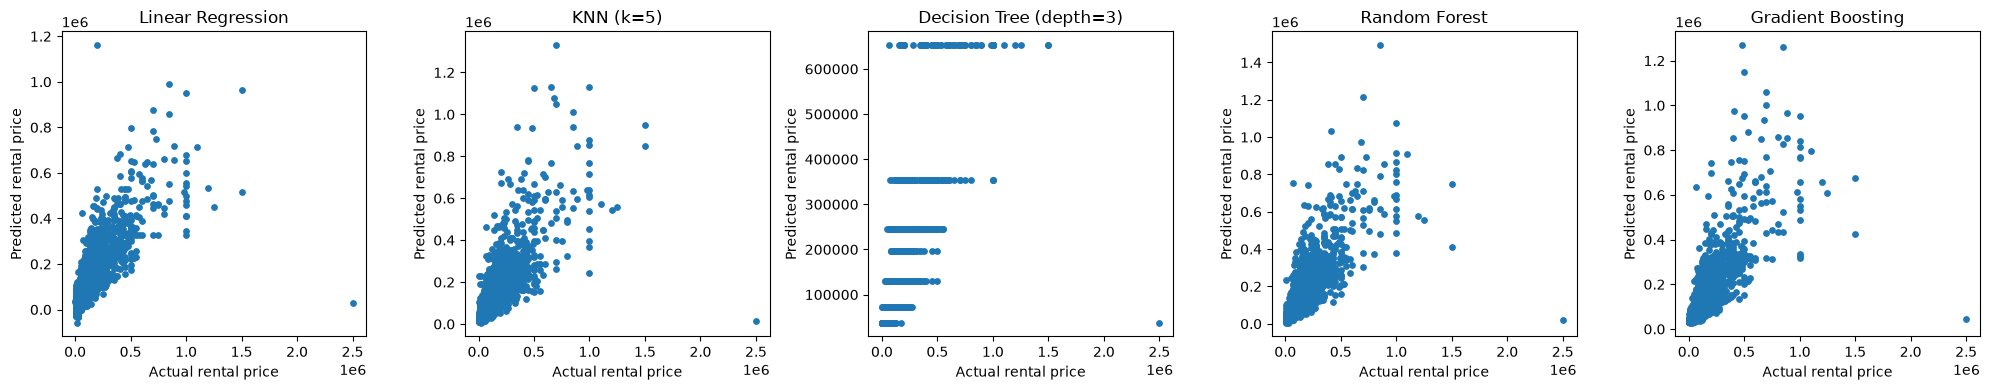

In [85]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt

# Define candidate models
models = {
    "Linear Regression": LinearRegression(),
    "KNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree (depth=3)": DecisionTreeRegressor(
        max_depth=3, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        min_samples_leaf=3, random_state=42
    )
}

# Fit each model using the existing preprocessing pipeline
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (name, model) in zip(axes, models.items()):
    scale = name in ["Linear Regression", "KNN (k=5)"]

    pipeline = rental_pipeline(model=model, scale=scale)
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    ax.scatter(y_test, predictions, s=15)
    ax.set_title(name)
    ax.set_xlabel("Actual rental price")
    ax.set_ylabel("Predicted rental price")

plt.tight_layout()
plt.show()

Inference: Comparison of Supervised Learning Models

The actual-versus-predicted plots compare five regression models for predicting Mumbai rental prices: Linear Regression, KNN, Decision Tree, Random Forest, and Gradient Boosting.

Linear Regression: Predictions generally follow the overall price pattern, but errors increase for expensive properties, suggesting difficulty capturing complex relationships.

KNN (k=5): Captures some variation in rental prices but shows noticeable prediction errors for high-priced properties and outliers.

Decision Tree (depth=3): Produces distinct horizontal prediction bands because of its limited depth. This indicates that the model is too simple to represent the full variation in rental prices.

Random Forest: Captures more complex patterns and produces a wider range of predictions, although substantial errors remain for some expensive properties.

Gradient Boosting: Captures nonlinear relationships and shows a prediction pattern similar to Random Forest, but some high-priced properties are still poorly estimated.

Comparing Supervised Models

In [86]:
from sklearn.model_selection import cross_validate

results = []

for name, model in models.items():
    scale = name in ["Linear Regression", "KNN (k=5)"]
    pipe = rental_pipeline(model=model, scale=scale)

    scores = cross_validate(
        pipe, X_train, y_train, cv=5,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "R²": scores["test_r2"].mean(),
        "MAE": -scores["test_mae"].mean(),
        "RMSE": -scores["test_rmse"].mean()
    })

results_df = pd.DataFrame(results).sort_values("R²", ascending=False)
display(results_df.round(3))

,Model,R²,MAE,RMSE
4,Gradient Boosting,0.639,38157.258,78631.995
0,Linear Regression,0.628,42471.453,79730.505
2,Decision Tree (depth=3),0.623,41810.028,80458.600
3,Random Forest,0.605,37464.319,82236.674
1,KNN (k=5),0.590,39969.481,83730.356


### Inference: Model Comparison

Five-fold cross-validation was used to compare the regression models using R², Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

- Higher R² indicates better explanatory performance.
- Lower MAE indicates smaller average prediction errors.
- Lower RMSE indicates fewer large prediction errors.

The results help identify promising models for predicting Mumbai rental prices. The model with the best cross-validation performance can be considered for further evaluation.

Visualize model performance

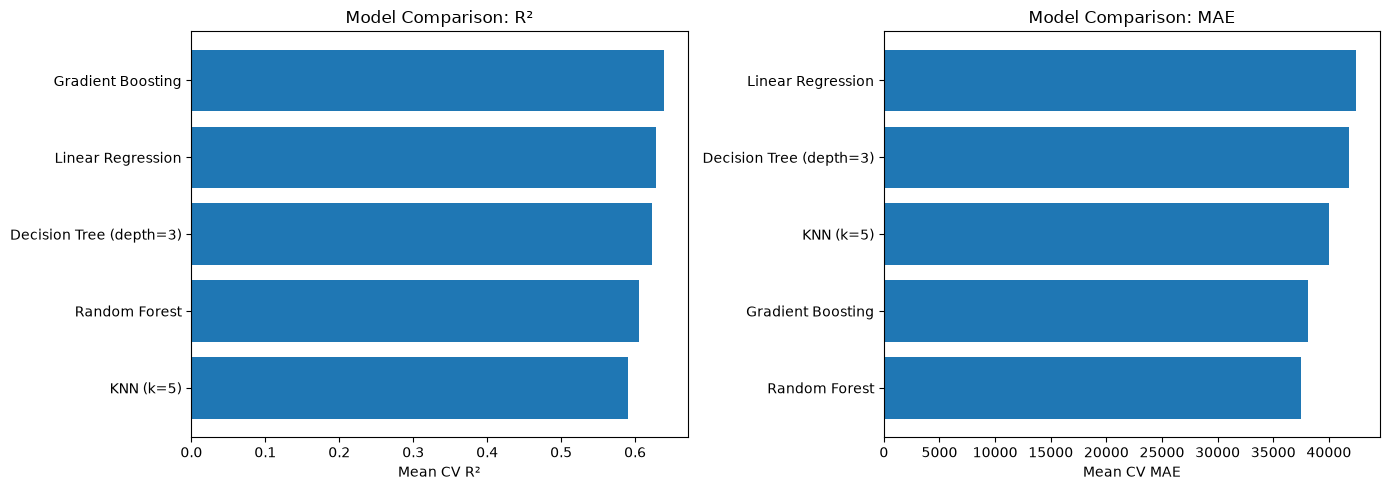

In [87]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results_sorted = results_df.sort_values("R²")
axes[0].barh(results_sorted["Model"], results_sorted["R²"])
axes[0].set_title("Model Comparison: R²")
axes[0].set_xlabel("Mean CV R²")

results_sorted = results_df.sort_values("MAE")
axes[1].barh(results_sorted["Model"], results_sorted["MAE"])
axes[1].set_title("Model Comparison: MAE")
axes[1].set_xlabel("Mean CV MAE")

plt.tight_layout()
plt.show()

## Model Comparison: Inference

We compared five models using 5-fold cross-validation on the training set, looking at mean R² and mean MAE.

- R² ranking: Gradient Boosting (~0.64) > Linear Regression (~0.63) > Decision Tree, depth 3 (~0.62) > Random Forest (~0.61) > KNN, k=5 (~0.59). The whole spread is only about 0.05.
- MAE ranking: Random Forest (~37.5k) and Gradient Boosting (~38k) are lowest. KNN (~40k) is in the middle. Decision Tree (~42k) and Linear Regression (~42.5k) are highest.
- The two metrics disagreeLinear Regression is second on R² but worst on MAE, while Random Forest is fourth on R² but best on MAE. R² is driven by squared error, so it is dominated by a few very expensive listings. MAE reflects accuracy on a typical listing. The tree ensembles appear to predict typical rents better, while the linear model copes relatively better with extreme values.
- Gradient Boosting is the most balanced.** It is first on R² and second on MAE, so it is the strongest candidate overall.
- Differences are small.The gaps between models (~0.05 R², ~5k MAE) are smaller than the fold-to-fold variation seen earlier (RMSE std ≈ 16k), so we should not claim a decisive winner from this chart alone.
- Every model is far better than the baseline.** The median baseline had a test MAE of ~67k and R² < 0, so property characteristics clearly carry signal.

Selecting the best candidate model

In [88]:
# Select the model with the highest mean cross-validation R²
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

scale = best_model_name in ["Linear Regression", "KNN (k=5)"]

best_pipeline = rental_pipeline(
    model=best_model,
    scale=scale
)

best_pipeline.fit(X_train, y_train)

print("Selected model:", best_model_name)
print("Mean CV R²:", round(results_df.iloc[0]["R²"], 3))
print("Mean CV MAE:", round(results_df.iloc[0]["MAE"], 3))
print("Mean CV RMSE:", round(results_df.iloc[0]["RMSE"], 3))

Selected model: Gradient Boosting
Mean CV R²: 0.639
Mean CV MAE: 38157.258
Mean CV RMSE: 78631.995


Mumbai Rental Price Analysis

Regression Metrics

In [89]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE measures average absolute error.")
print("RMSE penalizes large errors more heavily.")
print("R² measures how well the model explains price variation.")

MAE measures average absolute error.
RMSE penalizes large errors more heavily.
R² measures how well the model explains price variation.


### Inference: Regression Metrics

MAE, RMSE, and R² are used to evaluate rental price predictions. Lower MAE and RMSE indicate smaller prediction errors, while higher R² indicates better explanatory performance. 

Comparing models using cross-validation

In [90]:
from sklearn.model_selection import cross_validate, KFold
import pandas as pd

cv = KFold(n_splits=5, shuffle=True, random_state=42)

def compare_models(models):
    results = []

    for name, model in models.items():
        scale = name in ["Linear Regression", "Ridge Regression", "KNN (k=5)"]
        pipe = rental_pipeline(model=model, scale=scale)

        scores = cross_validate(
            pipe, X_train, y_train, cv=cv,
            scoring={
                "r2": "r2",
                "mae": "neg_mean_absolute_error",
                "rmse": "neg_root_mean_squared_error"
            },
            n_jobs=-1
        )

        results.append({
            "Model": name,
            "R²": scores["test_r2"].mean(),
            "MAE": -scores["test_mae"].mean(),
            "RMSE": -scores["test_rmse"].mean()
        })

    return pd.DataFrame(results).sort_values("R²", ascending=False)

### Inference: Cross-Validation

Five-fold cross-validation provides a more reliable comparison than a single validation split. The average scores help identify promising models while keeping the test dataset reserved for final evaluation.

In [91]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression

encoding_results = []

encoders = {
    "One-Hot": OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "Ordinal": OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
}

for name, encoder in encoders.items():
    pipe = rental_pipeline(
        model=LinearRegression(),
        scale=True,
        nominal_encoder=encoder
    )

    scores = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring="r2", n_jobs=-1
    )

    encoding_results.append({
        "Encoding": name,
        "Mean CV R²": scores["test_score"].mean()
    })

display(pd.DataFrame(encoding_results).round(4))

,Encoding,Mean CV R²
0,One-Hot,0.6203
1,Ordinal,0.6133


### Inference: Categorical Encoding

The gap is small, but One-Hot is also the conceptually correct choice, since categories like `Location` and `Facing` have no natural order and Ordinal encoding imposes a false one. We therefore keep One-Hot encoding in the pipeline.

Comparing model families

In [92]:
model_results = compare_models(models)
display(model_results.round(3))

,Model,R²,MAE,RMSE
0,Linear Regression,0.620,42467.323,80489.685
4,Gradient Boosting,0.619,38517.238,80735.054
2,Decision Tree (depth=3),0.615,41753.587,81208.097
3,Random Forest,0.588,37822.608,83658.966
1,KNN (k=5),0.575,40523.518,85320.378


### Inference: Model Families

Linear Regression (R² 0.620), Gradient Boosting (0.619) and Decision Tree (0.615) are effectively tied on R², so the data does not separate them clearly. Random Forest has the lowest MAE (about 37.8k) but a higher RMSE (about 83.7k), which suggests it predicts typical listings well but misses more on expensive ones. Linear Regression has the highest MAE (about 42.5k) but the lowest RMSE (about 80.5k), the reverse pattern. KNN is the weakest on R² and RMSE. Gradient Boosting offers the best balance, with near-top R² and the second-lowest MAE, so it remains the preferred candidate for tuning

Diagnose underfitting and overfitting

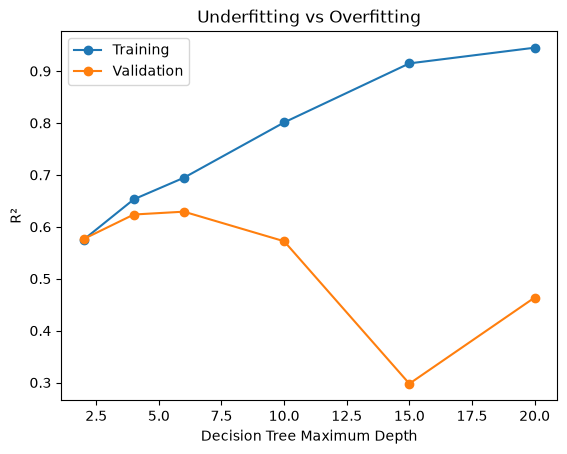

In [93]:
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt

tree_pipe = rental_pipeline(
    model=DecisionTreeRegressor(random_state=42),
    scale=False
)

depths = [2, 4, 6, 10, 15, 20]

train_scores, val_scores = validation_curve(
    tree_pipe, X_train, y_train,
    param_name="model__max_depth",
    param_range=depths,
    cv=cv, scoring="r2", n_jobs=-1
)

plt.plot(depths, train_scores.mean(axis=1), marker="o", label="Training")
plt.plot(depths, val_scores.mean(axis=1), marker="o", label="Validation")
plt.xlabel("Decision Tree Maximum Depth")
plt.ylabel("R²")
plt.title("Underfitting vs Overfitting")
plt.legend()
plt.show()

### Inference: Underfitting and Overfitting

Underfitting vs Overfitting (Decision Tree Depth)
-Depth 2: training and validation R² are both about 0.58, so the model is underfitting (too simple).
-Depth 4–6:validation R² peaks at about 0.63, the best bias–variance balance.
-Depth 10 and above:** training R² keeps climbing (up to about 0.95) while validation R² falls, a clear sign of overfitting.
-Validation R² drops to about 0.30 at depth 15. The model is memorising the training data.
-Conclusion: shallow tree (max depth around 4–6) generalises best, so depth should be constrained or tuned through cross-validation.

Hyperparameter tuning

In [94]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_pipe = rental_pipeline(
    model=RandomForestRegressor(random_state=42, n_jobs=1),
    scale=False
)

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipe,
    param_grid,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", round(grid_search.best_score_, 4))

best_pipeline = grid_search.best_estimator_

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Best CV R²: 0.6516


Final evaluation on the test set

In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

test_predictions = best_pipeline.predict(X_test)

print("Final Test R²:", round(r2_score(y_test, test_predictions), 4))
print("Final Test MAE:", round(mean_absolute_error(y_test, test_predictions), 2))
print("Final Test RMSE:", round(np.sqrt(mean_squared_error(y_test, test_predictions)), 2))

Final Test R²: 0.6187
Final Test MAE: 38044.93
Final Test RMSE: 82899.45


### Inference: Final Test Evaluation

The model explains about 62% of the variance in rent on unseen data.RMSE is more than twice the MAE, which suggests a small number of high-rent properties produce very large errors. 

The rent distribution is right-skewed, and luxury listings are hard to predict.

Possible improvements: log-transform the target, cap or treat outliers, and add richer location features.

Assessing importance of features

,Feature,Importance
0,Area_num,0.994419
1,BHK_num,0.031382
2,Bathrooms_num,0.021573
5,Facing,0.011127
3,Balconies_num,0.004625
4,Furnished_clean,0.003710
6,Location,0.000000
7,Property Type,-0.000696


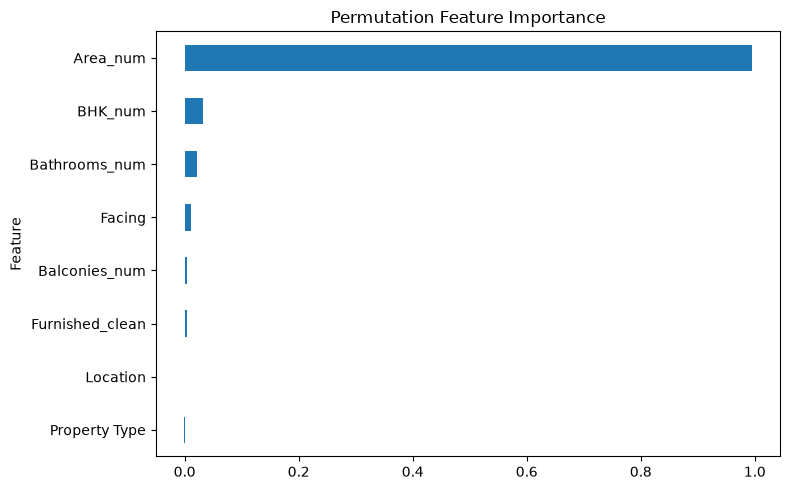

In [96]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_pipeline, X_test, y_test,
    scoring="r2", n_repeats=5,
    random_state=42, n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

importance_df.sort_values("Importance").plot(
    x="Feature", y="Importance",
    kind="barh", legend=False, figsize=(8, 5)
)
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

### Inference: Feature Importance

-Area (sq ft) dominates. Shuffling it removes nearly all of the model's predictive power, so it is by far the strongest driver of rent.
-BHK and bathrooms contribute slightly, but they are strongly correlated with area.
-Facing, balconies and furnishing status have negligible influence.
-Location and property type show about zero importance. However, location is normally a key rent driver in Mumbai. Likely causes are high-cardinality encoding that wasn't effective, or the model simply preferring area. It is worth revisiting how location is encoded (e.g., target encoding or grouping localities into zones).

## Final Model Evaluation – Visual Analysis

We evaluate the selected Decision Tree Regressor (max_depth=5)
using the held-out test dataset.

Two visualizations are used:
1. Actual vs Predicted Rental Prices
2. Distribution of Prediction Errors

These plots help assess prediction accuracy, systematic bias,
and the model's ability to generalize to unseen properties.

MAE:  40,528.67
RMSE: 83,764.35
R²:   0.611


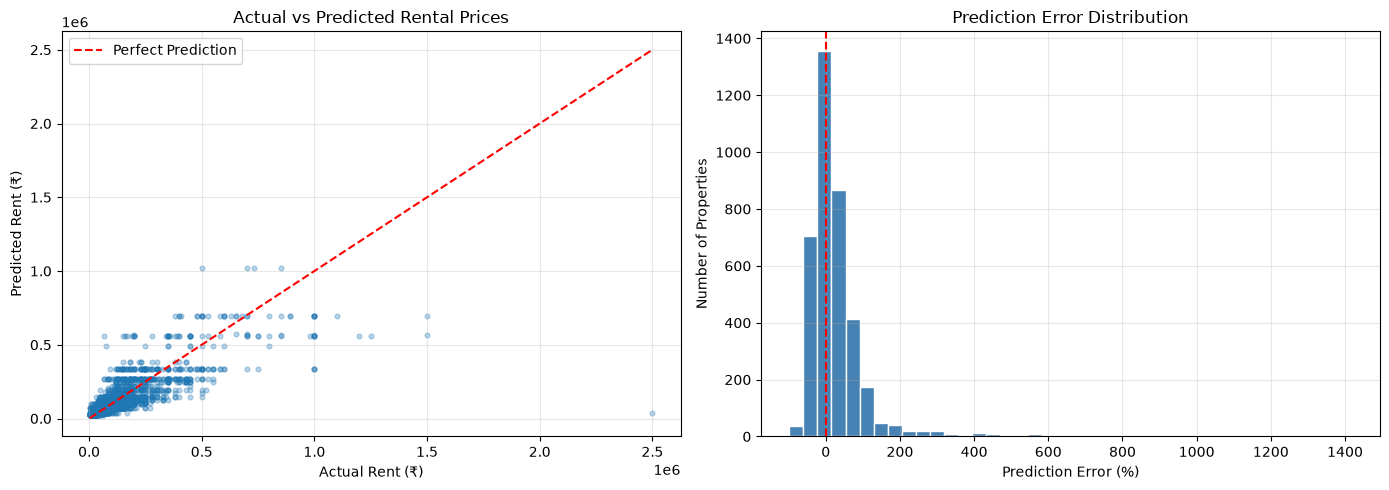

36.6% of properties predicted within ±20% of actual rent


In [98]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Final selected model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=5, random_state=42))
])

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

# Evaluation metrics
print(f"MAE:  {mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}")
print(f"R²:   {r2_score(y_test, y_pred):.3f}")

# Percentage prediction errors
actual = np.asarray(y_test)
errors = 100 * (y_pred - actual) / np.where(actual == 0, np.nan, actual)

# Create graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Actual vs Predicted
axes[0].scatter(actual, y_pred, alpha=0.3, s=12)

limits = [min(actual.min(), y_pred.min()),
          max(actual.max(), y_pred.max())]

axes[0].plot(limits, limits, "r--", label="Perfect Prediction")
axes[0].set(
    xlabel="Actual Rent (₹)",
    ylabel="Predicted Rent (₹)",
    title="Actual vs Predicted Rental Prices"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graph 2: Prediction Error Distribution
axes[1].hist(errors[np.isfinite(errors)], bins=40,
             color="steelblue", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(
    xlabel="Prediction Error (%)",
    ylabel="Number of Properties",
    title="Prediction Error Distribution"
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Prediction accuracy within ±20%
within_20 = np.nanmean(np.abs(errors) <= 20) * 100
print(f"{within_20:.1f}% of properties predicted within ±20% of actual rent")

Rental Price Error by Location — Horizontal Bar Chart

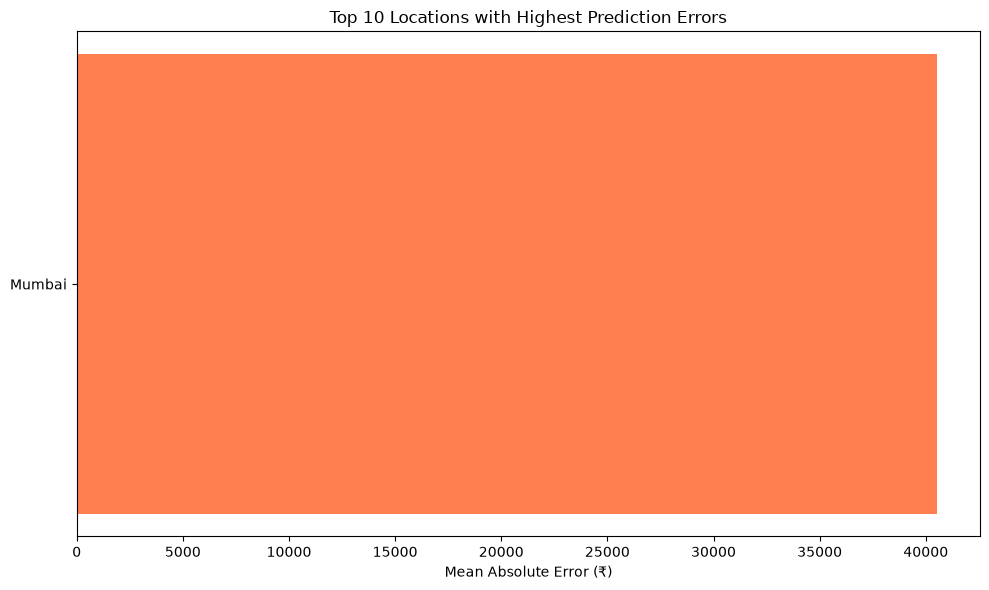

In [99]:
location_errors = pd.DataFrame({
    "Location": X_test["Location"].values,
    "Absolute Error": np.abs(np.asarray(y_test) - y_pred)
})

location_mae = (
    location_errors.groupby("Location")["Absolute Error"]
    .agg(["mean", "count"])
    .query("count >= 5")
    .sort_values("mean", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
plt.barh(location_mae.index, location_mae["mean"], color="coral")
plt.gca().invert_yaxis()

plt.xlabel("Mean Absolute Error (₹)")
plt.title("Top 10 Locations with Highest Prediction Errors")
plt.tight_layout()
plt.show()

### Inference: Location-wise Prediction Errors

Prediction accuracy varies across Mumbai locations.Areas with higher MAE indicate greater difficulty in estimating
rental prices, potentially due to differences in property characteristics or limited training observations.

Saving and using the final model

In [97]:
from pathlib import Path
import joblib

Path("models").mkdir(exist_ok=True)

joblib.dump(best_pipeline, "models/mumbai_rental_model.joblib")

loaded_model = joblib.load("models/mumbai_rental_model.joblib")

# Example: predict for one property from the test dataset
sample_property = X_test.iloc[[0]]
predicted_price = loaded_model.predict(sample_property)[0]

print(f"Predicted rental price: {predicted_price:,.2f}")
print(f"Actual rental price:    {y_test.iloc[0]:,.2f}")

Predicted rental price: 25,586.09
Actual rental price:    30,000.00


### Inference: Saving and Using the Model

The final pipeline is saved with `joblib` to `models/mumbai_rental_model.joblib`. Reloading it reproduces predictions without retraining.

Sample check: predicted rent is ₹25,586 against an actual ₹30,000, an error of about 15%. This is a reasonable single-point result, but one sample says little about overall accuracy; see the test metrics above.